# Telecom Network Performance & SLA Analytics

## 1. Business context
This project analyses network performance observations from a publicly hosted dataset. Key dimensions (number of SiteID identifiers, regions, technologies, dates and records) are computed dynamically in Sections 5–8 and summarised in Section 8. It evaluates key operational indicators, including uptime, downtime, network faults, and traffic volume, against a 99.9% uptime target to assess service availability and identify potential performance gaps.

The analysis is designed from a telecom network operations and project management perspective, focusing on regional and technology-wise performance comparisons, SLA compliance, and patterns in network reliability. It aims to identify areas with comparatively weaker performance, understand the extent of deviations from the target, and highlight observations that may require further operational investigation.

Using Python for data analysis and visualisation, the project translates SiteID-group observations into actionable insights to support performance monitoring, operational reporting, and data-driven decision-making.

## 2. Business objectives and analytical questions
1. **SLA position** - How far is observed uptime from the 99.9 % target at record, site, region and technology level?
2. **Regions and technologies** - Do they differ in uptime, downtime or faults once the number of observations behind each group is taken into account?
3. **Time pattern** - Is there a day-to-day pattern, or is daily variation what we would expect from sampling noise?
4. **Site exceptions** - Which SiteID groups are the best candidates for investigation first?
5. **Limits of the evidence** - What can and cannot be concluded from these fields (in particular, can root causes be identified)?

## 3. Dataset Sources, Description and Limitations

| Item | Detail |
|---|---|
| Network file | `network_perf_raw.csv` - one row per observation; expected columns `SiteID, Region, NetworkType, Uptime, Downtime, Faults, Traffic, Date`. SiteID identifiers are not confirmed as physical tower IDs. |
| Tower master | `towers_site_master.csv` - site attributes; its key column and scope are inspected in Section 5, not assumed |
| Data source | [Network-Performance-SLA GitHub repository](https://github.com/amrit1426/Network-Performance-SLA) |
| Loaded from | The raw CSV URLs in the project repository. If downloading fails, the notebook looks for the files in `data/raw/`, `../data/raw/` or the current folder |
| Row count, period, SiteID count | Computed in the notebook (Sections 5-8), not typed in by hand |
| Units | `Uptime` is treated as a percentage. `Downtime` is treated as minutes per record, following the original notebook's assumption. `Traffic` has no documented unit. Section 5 checks whether these fields are consistent |

**Main limitations (detailed in Section 16):** No incident causes, maintenance records or cost fields; the measurement window behind each record is not documented; the number of observations per site is small.


**Project scope and data disclaimer**

This project demonstrates a data analytics workflow using an illustrative telecom network performance dataset hosted in the project's GitHub repository. It should not be interpreted as an assessment of a real telecom operator's live network. The dataset contains 199 distinct SiteID identifiers, but these identifiers have not been established as unique physical tower identifiers. The 99.9% uptime figure is an assumed analytical benchmark rather than a verified contractual SLA.

---

In [1]:
# --- Imports ---------------------------------------------------------------import refrom pathlib import Pathimport numpy as npimport pandas as pdimport matplotlib.pyplot as pltimport matplotlib.dates as mdatesimport matplotlib.ticker as mtickimport seaborn as snsfrom scipy import statsfrom IPython.display import display, Markdown# Required packages: pandas, numpy, scipy, matplotlib, seaborn (plus Jupyter / IPython).#   pip install pandas numpy scipy matplotlib seaborn# --- Configuration ----------------------------------------------------------UPTIME_BENCHMARK = 99.9          # uptime target (%) used throughout (from the original project brief)MIN_OBS_PER_SITE = 3       # sites with fewer observations are not ranked (too little evidence)N_BOOT = 2000              # bootstrap resamples for confidence intervalsRNG_SEED = 42              # makes bootstrap results reproducibleMASTER_KEY_OVERRIDE = None # set to a column name if the tower-master key is not auto-detectedNETWORK_URL = "https://raw.githubusercontent.com/amrit1426/Network-Performance-SLA/refs/heads/main/data/raw/network_perf_raw.csv"MASTER_URL = "https://raw.githubusercontent.com/amrit1426/Network-Performance-SLA/refs/heads/main/data/raw/towers_site_master.csv"sns.set_theme(style="whitegrid")plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})pd.set_option("display.max_columns", 40)pd.set_option("display.width", 160)pd.set_option("display.max_colwidth", 110)def say(text):    """Render a Markdown string in the notebook output."""    display(Markdown(text))# Data is loaded from GitHub raw URLs (primary and only source).net_raw = pd.read_csv(NETWORK_URL)master_raw = pd.read_csv(MASTER_URL)print(f"Network data : {net_raw.shape[0]:,} rows x {net_raw.shape[1]} columns  <- remote: {NETWORK_URL}")print(f"Tower master : {master_raw.shape[0]:,} rows x {master_raw.shape[1]} columns  <- remote: {MASTER_URL}")

Network data : 1,000 rows x 8 columns  <- remote: https://raw.githubusercontent.com/amrit1426/Network-Performance-SLA/refs/heads/main/data/raw/network_perf_raw.csv
Tower master : 40 rows x 14 columns  <- remote: https://raw.githubusercontent.com/amrit1426/Network-Performance-SLA/refs/heads/main/data/raw/towers_site_master.csv


## 4. Data Loading and Configuration

Data is loaded from the GitHub repository's `data/raw/` folder via raw GitHub URLs. If remote loading fails, the notebook falls back to local copies in `data/raw/`, `../data/raw/` or the current working directory. The loading mechanism and fallback paths are defined in the configuration cell and should not be moved without updating the `LOCAL_DIRS` list.

## 5. Initial inspection and data-quality assessment
Checks come **before** any analysis. Nothing is deleted or imputed here; suspicious values are reported and any later exclusion is documented in Section 6.

In [2]:
# --- 5.1 Structure and types -------------------------------------------------
EXPECTED_COLS = ["SiteID", "Region", "NetworkType", "Uptime", "Downtime", "Faults", "Traffic", "Date"]
missing_cols = [c for c in EXPECTED_COLS if c not in net_raw.columns]
if missing_cols:
    raise KeyError(f"Network file is missing expected columns: {missing_cols}. Found: {list(net_raw.columns)}")

print("Columns found :", list(net_raw.columns))
print("Unexpected    :", [c for c in net_raw.columns if c not in EXPECTED_COLS] or "none")
display(net_raw.dtypes.astype(str).rename("dtype").to_frame().T)
display(net_raw.head())

Columns found : ['SiteID', 'Region', 'NetworkType', 'Uptime', 'Downtime', 'Faults', 'Traffic', 'Date']
Unexpected    : none


,SiteID,Region,NetworkType,Uptime,Downtime,Faults,Traffic,Date
dtype,str,str,str,float64,float64,int64,float64,str


,SiteID,Region,NetworkType,Uptime,Downtime,Faults,Traffic,Date
0,T103,West,4G,99.15,27.25,1,150.77,2026-01-11
1,T088,Central,3G,97.94,6.02,1,243.40,2026-01-22
2,T089,North,3G,97.28,10.37,2,225.14,2026-01-19
3,T108,West,4G,98.65,5.61,0,158.77,2026-01-04
4,T089,West,5G,97.78,3.08,2,275.80,2026-01-29


In [3]:
# --- 5.2 Standardise types (documented, non-destructive) ----------------------
df = net_raw.copy()

# Trim stray whitespace in text fields so "North " and "North" are not treated as different groups.
for col in ["SiteID", "Region", "NetworkType"]:
    original = df[col].astype("string")
    cleaned = original.str.strip()
    n_changed = int((cleaned.fillna("") != original.fillna("")).sum())
    df[col] = cleaned.astype(object)
    print(f"{col:<12} values changed by whitespace trimming: {n_changed}")

# Numeric fields: anything non-numeric becomes NaN and is counted, not silently ignored.
for col in ["Uptime", "Downtime", "Faults", "Traffic"]:
    before_na = df[col].isna().sum()
    df[col] = pd.to_numeric(df[col], errors="coerce")
    print(f"{col:<12} non-numeric entries converted to NaN: {int(df[col].isna().sum() - before_na)}")

# Dates: invalid strings become NaT and are counted.
before_na = df["Date"].isna().sum()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(f"{'Date':<12} unparseable dates converted to NaT: {int(df['Date'].isna().sum() - before_na)}")

print("\nDistinct Region values     :", sorted(df["Region"].dropna().unique()))
print("Distinct NetworkType values:", sorted(df["NetworkType"].dropna().unique()))

SiteID       values changed by whitespace trimming: 0
Region       values changed by whitespace trimming: 0
NetworkType  values changed by whitespace trimming: 0
Uptime       non-numeric entries converted to NaN: 0
Downtime     non-numeric entries converted to NaN: 0
Faults       non-numeric entries converted to NaN: 0
Traffic      non-numeric entries converted to NaN: 0
Date         unparseable dates converted to NaT: 0

Distinct Region values     : ['Central', 'East', 'North', 'South', 'West']
Distinct NetworkType values: ['3G', '4G', '5G']


In [4]:
# --- 5.3 Data-quality checks ---------------------------------------------------
checks = []
dq_flags = []   # plain-language issues that later sections and the summary refer to

def add_check(name, result, status, note=""):
    checks.append({"check": name, "result": result, "status": status, "note": note})
    if status == "REVIEW":
        dq_flags.append(f"{name}: {result}" + (f" - {note}" if note else ""))

n_rows = len(df)
add_check("Rows x columns", f"{n_rows:,} x {df.shape[1]}", "INFO")

miss = df[EXPECTED_COLS].isna().sum()
add_check("Missing values (all expected columns)", int(miss.sum()), "REVIEW" if miss.sum() else "OK",
          ", ".join(f"{c}={int(v)}" for c, v in miss.items() if v) )

add_check("Exact duplicate rows", int(df.duplicated().sum()), "REVIEW" if df.duplicated().sum() else "OK")

sd_dups = int(df.duplicated(["SiteID", "Date"], keep=False).sum())
add_check("Rows sharing a SiteID + Date with another row", sd_dups, "REVIEW" if sd_dups else "OK",
          "record grain is not one row per site per day" if sd_dups else "consistent with one row per site-day")

add_check("Unique sites / regions / technologies / dates",
          f"{df['SiteID'].nunique()} / {df['Region'].nunique()} / {df['NetworkType'].nunique()} / {df['Date'].nunique()}", "INFO")

up_bad = int(((df["Uptime"] < 0) | (df["Uptime"] > 100)).sum())
add_check("Uptime outside 0-100", up_bad, "REVIEW" if up_bad else "OK")
add_check("Uptime exactly 100", int((df["Uptime"] == 100).sum()), "INFO", "valid: no downtime in the window")
for col in ["Downtime", "Faults", "Traffic"]:
    neg = int((df[col] < 0).sum())
    add_check(f"Negative {col}", neg, "REVIEW" if neg else "OK")
for col in ["Downtime", "Faults", "Traffic"]:
    add_check(f"Zero {col}", int((df[col] == 0).sum()), "INFO",
              "treated as a valid observation unless other evidence says otherwise")
non_int = int((df["Faults"].dropna() % 1 != 0).sum())
add_check("Non-integer fault counts", non_int, "REVIEW" if non_int else "OK")

bad_id = int((~df["SiteID"].dropna().str.match(r"^[A-Za-z]+\d+$")).sum())
add_check("SiteID values not matching letters+digits pattern", bad_id, "REVIEW" if bad_id else "OK")

site_attr = df.groupby("SiteID").agg(n_regions=("Region", "nunique"), n_tech=("NetworkType", "nunique"), n_obs=("Date", "size"))
multi_region = int((site_attr["n_regions"] > 1).sum())
multi_tech = int((site_attr["n_tech"] > 1).sum())
add_check("Sites recorded under more than one Region", f"{multi_region} of {len(site_attr)}", "REVIEW" if multi_region else "OK",
          "SiteID is not a stable key for a physical site's region" if multi_region else "")
add_check("Sites recorded under more than one NetworkType", f"{multi_tech} of {len(site_attr)}", "REVIEW" if multi_tech else "OK",
          "a site can legitimately host several technologies, but check that this is intended" if multi_tech else "")
add_check("Observations per site (min / median / max)",
          f"{int(site_attr['n_obs'].min())} / {site_attr['n_obs'].median():.0f} / {int(site_attr['n_obs'].max())}", "INFO")
few = int((site_attr["n_obs"] < MIN_OBS_PER_SITE).sum())
add_check(f"Sites with fewer than {MIN_OBS_PER_SITE} observations", f"{few} of {len(site_attr)}", "REVIEW" if few else "OK",
          "site-level averages for these sites are unreliable" if few else "")

per_day = df.groupby("Date").size()
span_days = (df["Date"].max() - df["Date"].min()).days + 1
add_check("Dates with data / calendar days in range", f"{len(per_day)} / {span_days}", "OK" if len(per_day) == span_days else "REVIEW")
add_check("Records per day (min / max)", f"{int(per_day.min())} / {int(per_day.max())}", "INFO")

q1, q3 = df["Downtime"].quantile([0.25, 0.75])
iqr_out = int((df["Downtime"] > q3 + 1.5 * (q3 - q1)).sum())
add_check("Downtime values above Q3 + 1.5xIQR", iqr_out, "INFO", "flagged only; kept because long outages are plausible")

# Consistency of Uptime and Downtime. If every record covered the same window W,
# Downtime ~= W x (100 - Uptime) / 100, so the two would be strongly negatively correlated.
both = df[["Uptime", "Downtime"]].dropna()
corr_ud = both["Uptime"].corr(both["Downtime"])
partial = both[both["Uptime"] < 100]
implied_window = (partial["Downtime"] / ((100 - partial["Uptime"]) / 100)).replace([np.inf, -np.inf], np.nan).dropna()
iw_q = implied_window.quantile([0.25, 0.5, 0.75])
add_check("Correlation between Uptime and Downtime", f"{corr_ud:.3f}", "REVIEW" if abs(corr_ud) < 0.5 else "OK",
          "expected to be clearly negative if both describe the same time window" if abs(corr_ud) < 0.5 else "")
add_check("Implied measurement window, minutes (25th / median / 75th pct)",
          f"{iw_q[0.25]:,.0f} / {iw_q[0.5]:,.0f} / {iw_q[0.75]:,.0f}", "REVIEW" if (iw_q[0.75] / max(iw_q[0.25], 1e-9) > 3) else "INFO",
          "a 24-hour day is 1,440 min; a wide spread means Uptime and Downtime cannot both describe one fixed window")

dq_table = pd.DataFrame(checks)
display(dq_table)
print(f"\nChecks needing review: {len(dq_flags)}")

,check,result,status,note
0,Rows x columns,"1,000 x 8",INFO,
1,Missing values (all expected columns),0,OK,
2,Exact duplicate rows,0,OK,
3,Rows sharing a SiteID + Date with another row,146,REVIEW,record grain is not one row per site per day
4,Unique sites / regions / technologies / dates,199 / 5 / 3 / 30,INFO,
5,Uptime outside 0-100,0,OK,
6,Uptime exactly 100,110,INFO,valid: no downtime in the window
7,Negative Downtime,0,OK,
8,Negative Faults,0,OK,
9,Negative Traffic,0,OK,



Checks needing review: 6


In [5]:
# --- 5.4 Coverage across regions, technologies and sites ------------------------
say("**Records by region and technology** (coverage of each group):")
display(pd.crosstab(df["Region"], df["NetworkType"], margins=True))

say("**Distinct sites by region and technology:**")
display(df.pivot_table(index="Region", columns="NetworkType", values="SiteID", aggfunc="nunique", margins=True, margins_name="All (distinct)"))

say("**Distribution of observations per site:**")
display(site_attr["n_obs"].value_counts().sort_index().rename("sites").to_frame().T)

**Records by region and technology** (coverage of each group):

NetworkType,3G,4G,5G,All
Region,,,,
Central,77,68,57,202
East,59,71,73,203
North,68,62,56,186
South,74,60,62,196
West,61,91,61,213
All,339,352,309,1000


**Distinct sites by region and technology:**

NetworkType,3G,4G,5G,All (distinct)
Region,,,,
Central,61,56,50,127
East,55,62,63,132
North,61,55,49,129
South,60,54,50,124
West,52,72,52,130
All (distinct),171,168,158,199


**Distribution of observations per site:**

n_obs,1,2,3,4,5,6,7,8,9,10,11,12
sites,4,16,30,37,38,31,19,8,10,4,1,1


### 5.5 Reading the data-quality results
The table above is generated from the data, so read the `REVIEW` rows directly. Three questions matter for everything that follows:

* **Record grain.** If sites appear more than once per day, or under several regions or technologies, a row is an *observation*, not a *site-day*. Site-level results then describe a collection of observations, not one physical site.
* **Uptime vs Downtime.** If these two fields are not strongly negatively related, they were probably not derived from the same measurement window. In that case the notebook does **not** convert one into the other, and reports each as supplied.
* **Observations per site.** If most sites have only a handful of observations, site-level averages are noisy and must be read as screening signals, not verdicts.

In [6]:
# --- 5.6 Tower master: scope, keys and join validity ----------------------------
master = master_raw.copy()
print("Tower-master columns:", list(master.columns))

def find_master_key(frame):
    """Return the most likely site-identifier column, or None if it is ambiguous."""
    if MASTER_KEY_OVERRIDE:
        return MASTER_KEY_OVERRIDE
    norm = {c: re.sub(r"[^a-z0-9]", "", str(c).lower()) for c in frame.columns}
    exact = [c for c, n in norm.items() if n in {"siteid", "towerid", "siteidentifier", "sitecode", "towercode", "site"}]
    if len(exact) == 1:
        return exact[0]
    loose = [c for c, n in norm.items() if ("site" in n or "tower" in n) and "id" in n]
    return loose[0] if len(loose) == 1 else None

def norm_key(series):
    return series.astype("string").str.strip().str.upper()

MASTER_KEY = find_master_key(master)
MASTER_JOIN_OK = False
master_report = {}

if MASTER_KEY is None or MASTER_KEY not in master.columns:
    say("**Master key not identified automatically.** Set `MASTER_KEY_OVERRIDE` in the configuration cell. No join will be attempted.")
else:
    m_key = norm_key(master[MASTER_KEY])
    n_key = norm_key(df["SiteID"])
    net_sites, master_sites = set(n_key.dropna()), set(m_key.dropna())
    both_sites = net_sites & master_sites
    master_report = {
        "Master key column": MASTER_KEY,
        "Master rows": len(master),
        "Null keys in master": int(m_key.isna().sum()),
        "Duplicate keys in master": int(m_key.dropna().duplicated().sum()),
        "Distinct network sites": len(net_sites),
        "Distinct master sites": len(master_sites),
        "Network sites found in master": len(both_sites),
        "Network sites missing from master": len(net_sites - both_sites),
        "Master sites absent from network data": len(master_sites - both_sites),
        "Site coverage (network sites in master)": f"{100 * len(both_sites) / max(len(net_sites), 1):.1f}%",
        "Record coverage (network rows whose site is in master)": f"{100 * n_key.isin(master_sites).mean():.1f}%",
        "Null SiteID in network data": int(n_key.isna().sum()),
    }
    master_unique = master_report["Duplicate keys in master"] == 0 and master_report["Null keys in master"] == 0
    if len(both_sites) == 0:
        relationship = "Not established — zero matching identifiers."
    elif master_unique:
        relationship = "one-to-many (master unique; network has repeated sites)"
    else:
        relationship = "many-to-many or ambiguous (master key is not unique)"
    master_report["Join relationship (master : network)"] = relationship
    display(pd.Series(master_report, name="value").to_frame())
    print("Sample network IDs:", sorted(net_sites)[:5], "| sample master IDs:", sorted(master_sites)[:5])
    MASTER_JOIN_OK = master_unique and len(both_sites) > 0

    if MASTER_JOIN_OK:
        say(f"The master key is unique and overlaps with the network data, so attributes can be attached **where a site exists in the master**. "
            f"Coverage is partial ({master_report['Site coverage (network sites in master)']} of network sites), so master attributes are used only to enrich "
            f"the site exception list in Section 13 and are **not** used for network-wide comparisons, which would represent only the covered subset.")
    else:
        say("The master cannot be joined safely (non-unique keys or no overlap). It is not used. No master records are invented or imputed.")


Tower-master columns: ['tower_id', 'site_name', 'region', 'city', 'lat', 'lon', 'vendor', 'technology', 'backhaul', 'backup_power', 'backup_hours', 'field_team', 'traffic_weight', 'enterprise_customers']


,value
Master key column,tower_id
Master rows,40
Null keys in master,0
Duplicate keys in master,0
Distinct network sites,199
Distinct master sites,40
Network sites found in master,0
Network sites missing from master,199
Master sites absent from network data,40
Site coverage (network sites in master),0.0%


Sample network IDs: ['T001', 'T002', 'T003', 'T004', 'T005'] | sample master IDs: ['EC-001', 'EC-002', 'EC-003', 'FS-001', 'FS-002']


The master cannot be joined safely (non-unique keys or no overlap). It is not used. No master records are invented or imputed.

## 6. Cleaning and validation decisions
Decisions are rule-based and documented, and every exclusion is counted:

| Decision | Rule | Reason |
|---|---|---|
| Whitespace in text fields | Trimmed | Prevents false duplicate categories |
| Rows with missing key fields | Excluded from KPI calculations | A KPI cannot be computed without them |
| Impossible values (Uptime outside 0-100; negative Downtime, Faults, Traffic) | Excluded | Not physically meaningful |
| Zero downtime / zero faults / Uptime = 100 | **Kept** | Valid observations of a healthy period |
| Statistical outliers in Downtime | **Kept** | Long outages are plausible; flagged, not removed |
| Duplicates / repeated site-dates | **Kept and reported** | Cannot tell a data-entry duplicate from a second valid observation without more documentation |
| Uptime vs Downtime inconsistencies | **Kept; fields analysed separately** | No defensible way to decide which field is right |

In [7]:
# --- 6.1 Apply the documented rules ----------------------------------------------
key_fields = ["SiteID", "Region", "NetworkType", "Date", "Uptime", "Downtime", "Faults"]
missing_key = df[key_fields].isna().any(axis=1)
impossible = (df["Uptime"].lt(0) | df["Uptime"].gt(100) | df["Downtime"].lt(0) | df["Faults"].lt(0) | df["Traffic"].lt(0))
exclude = missing_key | impossible

print(f"Rows before cleaning        : {len(df):,}")
print(f"Excluded - missing key field: {int(missing_key.sum())}")
print(f"Excluded - impossible values: {int((impossible & ~missing_key).sum())}")

data = df.loc[~exclude].copy()
data["below_benchmark"] = data["Uptime"] < UPTIME_BENCHMARK          # record-level breach flag (analytical proxy)
data["Day"] = data["Date"].dt.normalize()
print(f"Rows used in analysis       : {len(data):,}  ({100 * len(data) / len(df):.1f}% of raw rows)")
assert data["Uptime"].between(0, 100).all() and (data[["Downtime", "Faults"]] >= 0).all().all()


Rows before cleaning        : 1,000
Excluded - missing key field: 0
Excluded - impossible values: 0
Rows used in analysis       : 1,000  (100.0% of raw rows)


## 7. KPI definitions and aggregation logic

| KPI | Definition | Unit | Level | How to read it |
|---|---|---|---|---|
| **Average uptime** | Mean of the `Uptime` field | % | Record, then grouped by site / region / technology / day | Simple (unweighted) mean of observations; the measurement window per record is undocumented |
| **Uptime gap to target** | `99.9 - average uptime` | percentage points (pp) | Same as above | Positive = below target |
| **Record-level breach rate** | Share of records with `Uptime < 99.9` | % of records | Any grouping | Proxy for how often a single observation misses the target |
| **SiteID-group uptime** | Mean uptime of a SiteID group's observations | % | SiteID group | **Proxy**, not contractual SLA compliance; a real SLA needs the contract's period and formula |
| **SiteID-group meets target (proxy)** | SiteID-group uptime >= 99.9 | yes / no | SiteID group | Counted only for SiteID groups with at least `MIN_OBS_PER_SITE` observations |
| **Total downtime** | Sum of `Downtime` | minutes | Any grouping | Depends on how many records a group has (exposure) |
| **Average downtime per record** | Mean of `Downtime` | minutes / record | Any grouping | Descriptive per-record comparison; observation durations are undocumented |
| **Total faults** | Sum of `Faults` | count | Any grouping | Depends on exposure |
| **Faults per record** | Mean of `Faults` | faults / record | Any grouping | Descriptive per-record comparison; observation durations are undocumented |
| **Average traffic** | Mean of `Traffic` | unspecified | Any grouping | Unit not documented; use only for relative comparison |
| **Records share vs downtime share** | Group's share of all records vs share of all downtime | % | Region, technology | A higher downtime share than record share indicates comparatively higher recorded downtime; observation durations are undocumented |

**Not calculable from these fields:**
* *Contractual monthly SLA compliance* - needs the contract's measurement period, exclusions and formula; sites also lack full daily coverage.
* *Total outage duration from uptime* - the window behind each record is undocumented and Section 5 tests its consistency.
* *Mean time to repair, repeat-incident rate, cost per incident* - no incident or cost fields.

**Denominator caveat.** "Per record" treats each record as equal exposure. That holds only if every record covers the same period and site, which the data cannot confirm.


In [8]:
# --- 7.1 Aggregation helpers and KPI tables (computed once, reused below) --------
def summarize(frame, by):
    """KPI table for any grouping column."""
    out = frame.groupby(by).agg(
        records=("SiteID", "size"), sites=("SiteID", "nunique"), days=("Day", "nunique"),
        avg_uptime=("Uptime", "mean"), median_uptime=("Uptime", "median"),
        pct_records_below_benchmark=("below_benchmark", "mean"),
        total_downtime=("Downtime", "sum"), avg_downtime=("Downtime", "mean"),
        total_faults=("Faults", "sum"), faults_per_record=("Faults", "mean"),
        avg_traffic=("Traffic", "mean"),
    )
    out["pct_records_below_benchmark"] *= 100
    out["uptime_gap_pp"] = UPTIME_BENCHMARK - out["avg_uptime"]
    out["records_share_pct"] = 100 * out["records"] / out["records"].sum()
    out["downtime_share_pct"] = 100 * out["total_downtime"] / out["total_downtime"].sum()
    out["faults_share_pct"] = 100 * out["total_faults"] / out["total_faults"].sum()
    return out

def leader_table(tbl):
    """Which group leads on each metric - these answer different business questions."""
    spec = [("Highest total downtime", "total_downtime", "max"), ("Highest avg downtime per record", "avg_downtime", "max"),
            ("Highest total faults", "total_faults", "max"), ("Highest faults per record", "faults_per_record", "max"),
            ("Highest avg uptime", "avg_uptime", "max"), ("Lowest avg uptime", "avg_uptime", "min"),
            ("Highest share of records below target", "pct_records_below_benchmark", "max")]
    rows = []
    for label, col, how in spec:
        idx = tbl[col].idxmax() if how == "max" else tbl[col].idxmin()
        rows.append({"question": label, "group": idx, "value": round(float(tbl.loc[idx, col]), 2)})
    return pd.DataFrame(rows)

overall = summarize(data.assign(Scope="Whole network"), "Scope")
by_region = summarize(data, "Region")
by_tech = summarize(data, "NetworkType")

# SiteID-group table. Region / technology are listed as seen, because a SiteID may span several.
site_stats = data.groupby("SiteID").agg(
    n_obs=("Date", "size"),
    regions=("Region", lambda s: "/".join(sorted(s.unique()))),
    technologies=("NetworkType", lambda s: "/".join(sorted(s.unique()))),
    avg_uptime=("Uptime", "mean"), min_uptime=("Uptime", "min"),
    pct_obs_below_benchmark=("below_benchmark", "mean"),
    total_downtime=("Downtime", "sum"), avg_downtime=("Downtime", "mean"),
    total_faults=("Faults", "sum"), faults_per_obs=("Faults", "mean"),
)
site_stats["pct_obs_below_benchmark"] *= 100
site_stats["uptime_gap_pp"] = UPTIME_BENCHMARK - site_stats["avg_uptime"]
eligible = site_stats[site_stats["n_obs"] >= MIN_OBS_PER_SITE].copy()
eligible["meets_target_proxy"] = eligible["avg_uptime"] >= UPTIME_BENCHMARK

# Transparent heuristic priority score: mean percentile rank of (low uptime, high avg downtime, high faults per obs).
eligible["priority_score"] = pd.concat([
    (-eligible["avg_uptime"]).rank(pct=True),
    eligible["avg_downtime"].rank(pct=True),
    eligible["faults_per_obs"].rank(pct=True)], axis=1).mean(axis=1)

daily = data.groupby("Day").agg(
    records=("SiteID", "size"), sites=("SiteID", "nunique"), avg_uptime=("Uptime", "mean"),
    pct_records_below_benchmark=("below_benchmark", "mean"), avg_downtime=("Downtime", "mean"),
    total_downtime=("Downtime", "sum"), total_faults=("Faults", "sum"), faults_per_record=("Faults", "mean"))
daily["pct_records_below_benchmark"] *= 100

# --- 7.2 Cluster bootstrap: resample whole sites so repeated observations of a site stay together
def cluster_bootstrap_ci(frame, group_col, value_col, n_boot=N_BOOT, seed=RNG_SEED):
    """95% CI of group means, resampling SiteIDs (not rows) to respect within-site dependence."""
    rng = np.random.default_rng(seed)
    sums = frame.pivot_table(index="SiteID", columns=group_col, values=value_col, aggfunc="sum", fill_value=0)
    cnts = frame.pivot_table(index="SiteID", columns=group_col, values=value_col, aggfunc="count", fill_value=0)
    idx = rng.integers(0, len(sums), size=(n_boot, len(sums)))
    s_tot, c_tot = sums.to_numpy()[idx].sum(axis=1), cnts.to_numpy()[idx].sum(axis=1)
    means = s_tot / np.where(c_tot == 0, np.nan, c_tot)
    lo, hi = np.nanpercentile(means, [2.5, 97.5], axis=0)
    return pd.DataFrame({"lo": lo, "hi": hi}, index=sums.columns)

# --- 7.3 Statistical helpers ---------------------------------------------------------
def holm_adjust(pvals):
    """Holm-Bonferroni adjusted p-values (controls the family-wise error rate)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def site_icc(frame, value_col):
    """Intraclass correlation by SiteID: how alike observations of the same site are (0 = not at all)."""
    groups = [g[value_col].to_numpy() for _, g in frame.groupby("SiteID")]
    k, N = len(groups), sum(len(g) for g in groups)
    if k < 2 or N <= k:
        return np.nan
    grand = frame[value_col].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)
    msb, msw = ssb / (k - 1), ssw / (N - k)
    n0 = (N - sum(len(g) ** 2 for g in groups) / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

def compare_groups(frame, group_col, value_col):
    """One-way comparison of a metric across groups, with assumption checks and effect size."""
    groups = {k: g[value_col].to_numpy() for k, g in frame.groupby(group_col)}
    desc = frame.groupby(group_col)[value_col].agg(n="size", mean="mean", sd="std", median="median")
    f_stat, p_anova = stats.f_oneway(*groups.values())
    h_stat, p_kw = stats.kruskal(*groups.values())
    _, p_levene = stats.levene(*groups.values(), center="median")
    grand = frame[value_col].mean()
    eta_sq = sum(len(v) * (v.mean() - grand) ** 2 for v in groups.values()) / ((frame[value_col] - grand) ** 2).sum()
    return {"desc": desc, "F": f_stat, "p_anova": p_anova, "H": h_stat, "p_kruskal": p_kw, "p_levene": p_levene,
            "eta_sq": eta_sq, "skew": frame[value_col].skew(), "icc_site": site_icc(frame, value_col),
            "range_of_means": desc["mean"].max() - desc["mean"].min()}

TESTS = [("Uptime", "Region"), ("Downtime", "NetworkType"), ("Uptime", "NetworkType"), ("Downtime", "Region")]
stat_results = {t: compare_groups(data, t[1], t[0]) for t in TESTS}
for key, adj in zip(TESTS, holm_adjust([stat_results[t]["p_anova"] for t in TESTS])):
    stat_results[key]["p_anova_holm"] = adj
for key, adj in zip(TESTS, holm_adjust([stat_results[t]["p_kruskal"] for t in TESTS])):
    stat_results[key]["p_kruskal_holm"] = adj

def eta_label(e):
    return "negligible" if e < 0.01 else "small" if e < 0.06 else "medium" if e < 0.14 else "large"

print("KPI tables ready:", ", ".join(["overall", "by_region", "by_tech", "site_stats", "daily", "stat_results"]))
print(f"Sites with >= {MIN_OBS_PER_SITE} observations (eligible for ranking): {len(eligible)} of {len(site_stats)}")


KPI tables ready: overall, by_region, by_tech, site_stats, daily, stat_results
Sites with >= 3 observations (eligible for ranking): 179 of 199


## 8. Executive summary
The summary below is **generated from the calculated results** each time the notebook runs, so names, figures and wording cannot drift apart from the analysis.

In [9]:
def stat_sentence(key):
    r, (val, grp) = stat_results[key], key
    verdict = "a statistically detectable difference" if r["p_anova_holm"] < 0.05 else "no statistically detectable difference"
    return (f"{val} by {grp}: **{verdict}** (ANOVA p = {r['p_anova']:.3f}, Holm-adjusted {r['p_anova_holm']:.3f}; "
            f"effect size eta-squared = {r['eta_sq']:.3f}, {eta_label(r['eta_sq'])}; spread of group means = {r['range_of_means']:.2f})")

ov = overall.iloc[0]
period = f"{data['Date'].min():%d %b %Y} to {data['Date'].max():%d %b %Y}"
n_elig, n_meet = len(eligible), int(eligible["meets_target_proxy"].sum())
reg_lo, reg_hi = by_region["avg_uptime"].idxmin(), by_region["avg_uptime"].idxmax()
reg_spread = by_region["avg_uptime"].max() - by_region["avg_uptime"].min()
t_total, t_avg = by_tech["total_downtime"].idxmax(), by_tech["avg_downtime"].idxmax()
t_faults, t_fpr = by_tech["total_faults"].idxmax(), by_tech["faults_per_record"].idxmax()
t_lowup = by_tech["avg_uptime"].idxmin()
top_sites = eligible.sort_values("priority_score", ascending=False).head(5).index.tolist()

lines = [
    "### Dataset-derived findings",
    f"* **Scope.** {len(data):,} observations from {data['SiteID'].nunique()} distinct SiteIDs, {data['Region'].nunique()} regions and "
    f"{data['NetworkType'].nunique()} technologies, covering {period} ({data['Day'].nunique()} days). "
    f"{len(df) - len(data)} raw rows were excluded under the Section 6 rules.",
    f"* **Overall uptime.** Mean uptime is **{ov['avg_uptime']:.2f}%**, which is **{ov['uptime_gap_pp']:.2f} pp below** the {UPTIME_BENCHMARK}% target. "
    f"{ov['pct_records_below_benchmark']:.1f}% of individual records are below the target (record-level proxy).",
    f"* **SiteID-group level (proxy).** Of {n_elig} SiteID groups with at least {MIN_OBS_PER_SITE} observations, **{n_meet} ({100 * n_meet / max(n_elig, 1):.1f}%)** have average uptime at or above the target and "
    f"{n_elig - n_meet} ({100 * (n_elig - n_meet) / max(n_elig, 1):.1f}%) are below it. This is an analytical proxy, not contractual SLA compliance.",
    f"* **Regions.** Lowest average uptime: **{reg_lo}** ({by_region.loc[reg_lo, 'avg_uptime']:.2f}%); highest: {reg_hi} ({by_region.loc[reg_hi, 'avg_uptime']:.2f}%). "
    f"The spread between best and worst region is {reg_spread:.2f} pp, against a network-wide gap to target of {ov['uptime_gap_pp']:.2f} pp.",
    f"* **Technologies** (different metrics, different leaders): highest total downtime = **{t_total}**; highest average downtime per record = **{t_avg}**; "
    f"highest total faults = **{t_faults}**; highest faults per record = **{t_fpr}**; lowest average uptime = **{t_lowup}**. "
    f"({t_total} holds {by_tech.loc[t_total, 'records_share_pct']:.1f}% of records and {by_tech.loc[t_total, 'downtime_share_pct']:.1f}% of downtime.)",
    "* **Statistical checks** (observation level; see Section 14 for assumptions and limits):",
] + ["    * " + stat_sentence(t) for t in TESTS] + [
    f"* **Highest-priority SiteID groups for review** (heuristic score, Section 13): {', '.join(top_sites)}.",
    "* **Root causes cannot be established.** The data has no cause, incident, maintenance, power or cost fields.",
]
if dq_flags:
    lines += ["", f"### Data-quality caveats ({len(dq_flags)} items flagged for review in Section 5)"] + ["* " + f for f in dq_flags]
lines += ["", "_Uptime is treated as a percentage; Downtime as minutes per record; the measurement window behind each record is undocumented. "
          "All SLA figures here are analytical proxies._"]
say("\n".join(lines))


### Dataset-derived findings
* **Scope.** 1,000 observations from 199 distinct SiteIDs, 5 regions and 3 technologies, covering 01 Jan 2026 to 30 Jan 2026 (30 days). 0 raw rows were excluded under the Section 6 rules.
* **Overall uptime.** Mean uptime is **98.48%**, which is **1.42 pp below** the 99.9% target. 87.2% of individual records are below the target (record-level proxy).
* **SiteID-group level (proxy).** Of 179 SiteID groups with at least 3 observations, **0 (0.0%)** have average uptime at or above the target and 179 (100.0%) are below it. This is an analytical proxy, not contractual SLA compliance.
* **Regions.** Lowest average uptime: **West** (98.38%); highest: Central (98.57%). The spread between best and worst region is 0.19 pp, against a network-wide gap to target of 1.42 pp.
* **Technologies** (different metrics, different leaders): highest total downtime = **4G**; highest average downtime per record = **5G**; highest total faults = **4G**; highest faults per record = **4G**; lowest average uptime = **5G**. (4G holds 35.2% of records and 35.2% of downtime.)
* **Statistical checks** (observation level; see Section 14 for assumptions and limits):
    * Uptime by Region: **no statistically detectable difference** (ANOVA p = 0.446, Holm-adjusted 0.914; effect size eta-squared = 0.004, negligible; spread of group means = 0.19)
    * Downtime by NetworkType: **no statistically detectable difference** (ANOVA p = 0.952, Holm-adjusted 0.952; effect size eta-squared = 0.000, negligible; spread of group means = 0.76)
    * Uptime by NetworkType: **no statistically detectable difference** (ANOVA p = 0.084, Holm-adjusted 0.335; effect size eta-squared = 0.005, negligible; spread of group means = 0.18)
    * Downtime by Region: **no statistically detectable difference** (ANOVA p = 0.305, Holm-adjusted 0.914; effect size eta-squared = 0.005, negligible; spread of group means = 5.90)
* **Highest-priority SiteID groups for review** (heuristic score, Section 13): T115, T037, T044, T075, T072.
* **Root causes cannot be established.** The data has no cause, incident, maintenance, power or cost fields.

### Data-quality caveats (6 items flagged for review in Section 5)
* Rows sharing a SiteID + Date with another row: 146 - record grain is not one row per site per day
* Sites recorded under more than one Region: 189 of 199 - SiteID is not a stable key for a physical site's region
* Sites recorded under more than one NetworkType: 187 of 199 - a site can legitimately host several technologies, but check that this is intended
* Sites with fewer than 3 observations: 20 of 199 - site-level averages for these sites are unreliable
* Correlation between Uptime and Downtime: 0.016 - expected to be clearly negative if both describe the same time window
* Implied measurement window, minutes (25th / median / 75th pct): 474 / 1,312 / 3,289 - a 24-hour day is 1,440 min; a wide spread means Uptime and Downtime cannot both describe one fixed window

_Uptime is treated as a percentage; Downtime as minutes per record; the measurement window behind each record is undocumented. All SLA figures here are analytical proxies._

## 9. Overall network performance

In [10]:
display(overall.drop(columns=["records_share_pct", "downtime_share_pct", "faults_share_pct"]).T.rename(columns={"Whole network": "value"}).round(2))

q = data["Uptime"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2)
print("Record-level uptime percentiles (5th / 25th / 50th / 75th / 95th):", " / ".join(f"{v:.2f}" for v in q))
print(f"Records at or above {UPTIME_BENCHMARK}%: {int((~data['below_benchmark']).sum()):,} of {len(data):,} "
      f"({100 * (~data['below_benchmark']).mean():.1f}%)")

say(f"**SiteID-group benchmark comparison** (SiteID groups with at least {MIN_OBS_PER_SITE} observations; {len(site_stats) - len(eligible)} sites excluded for too little data):")
display(pd.DataFrame({
    "sites": [len(eligible), int(eligible["meets_target_proxy"].sum()), int((~eligible["meets_target_proxy"]).sum())],
    "share_of_eligible_%": [100.0, 100 * eligible["meets_target_proxy"].mean(), 100 * (~eligible["meets_target_proxy"]).mean()],
}, index=["Eligible SiteID groups", f"Average uptime >= {UPTIME_BENCHMARK}%", f"Average uptime < {UPTIME_BENCHMARK}%"]).round(1))
print(f"SiteID groups with no record below target: {int((eligible['pct_obs_below_benchmark'] == 0).sum())} of {len(eligible)}")
print(f"Median SiteID-group gap to target: {eligible['uptime_gap_pp'].median():.2f} pp")


Scope,value
records,1000.00
sites,199.00
days,30.00
avg_uptime,98.48
median_uptime,98.55
pct_records_below_benchmark,87.20
total_downtime,29825.20
avg_downtime,29.83
total_faults,1985.00
faults_per_record,1.98


Record-level uptime percentiles (5th / 25th / 50th / 75th / 95th): 96.59 / 97.77 / 98.55 / 99.32 / 100.00
Records at or above 99.9%: 128 of 1,000 (12.8%)


**SiteID-group benchmark comparison** (SiteID groups with at least 3 observations; 20 sites excluded for too little data):

,sites,share_of_eligible_%
Eligible SiteID groups,179,100.0
Average uptime >= 99.9%,0,0.0
Average uptime < 99.9%,179,100.0


SiteID groups with no record below target: 0 of 179
Median SiteID-group gap to target: 1.41 pp


**How to read this.** The mean uptime and the share of records below target answer different questions: the first measures the *size* of the shortfall, the second its *frequency*. The site-level figures show whether the shortfall is spread across most sites or concentrated in a few. All three are proxies; a contractual SLA calculation would need the contract's measurement period and formula.

## 10. Regional performance against the assumed benchmark


,records,sites,avg_uptime,uptime_gap_pp,pct_records_below_benchmark,total_downtime,avg_downtime,total_faults,faults_per_record,records_share_pct,downtime_share_pct
Region,,,,,,,,,,,
West,213,130,98.38,1.52,87.32,6066.00,28.48,385,1.81,21.3,20.34
North,186,129,98.47,1.43,89.78,5215.30,28.04,399,2.15,18.6,17.49
East,203,132,98.48,1.42,89.66,6889.92,33.94,409,2.01,20.3,23.10
South,196,124,98.53,1.37,85.20,5689.65,29.03,394,2.01,19.6,19.08
Central,202,127,98.57,1.33,84.16,5964.33,29.53,398,1.97,20.2,20.00


**Which region leads on each metric** (these are different questions, so the leaders differ):

,question,group,value
0,Highest total downtime,East,6889.92
1,Highest avg downtime per record,East,33.94
2,Highest total faults,East,409.00
3,Highest faults per record,North,2.15
4,Highest avg uptime,Central,98.57
5,Lowest avg uptime,West,98.38
6,Highest share of records below target,North,89.78


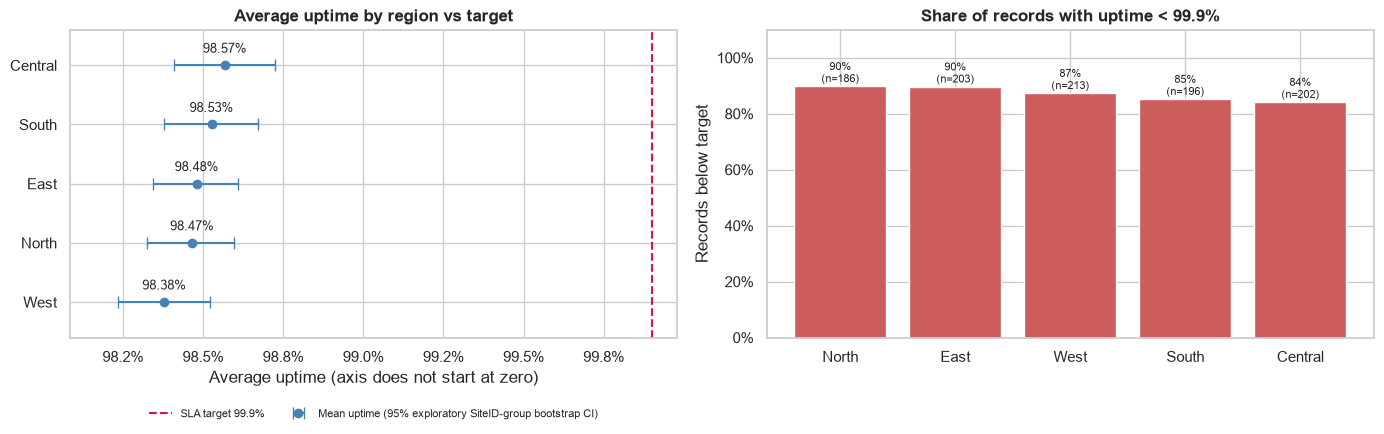

**Interpretation.** West has the lowest average uptime (98.38%) and Central the highest (98.57%): a spread of 0.19 pp. Every region's gap to target is between 1.33 and 1.52 pp, so the shortfall is similar in all regions. Regional comparison is not statistically distinguishable (Holm-adjusted p = 0.914). Check whether the confidence intervals overlap before treating a region as genuinely worse. **Next step:** use regional ranking only as a screening hint; the site-level view (Section 13) is more actionable.

In [11]:
reg_cols = ["records", "sites", "avg_uptime", "uptime_gap_pp", "pct_records_below_benchmark",
            "total_downtime", "avg_downtime", "total_faults", "faults_per_record", "records_share_pct", "downtime_share_pct"]
display(by_region.sort_values("avg_uptime")[reg_cols].round(2))
say("**Which region leads on each metric** (these are different questions, so the leaders differ):")
display(leader_table(by_region))

ci_reg = cluster_bootstrap_ci(data, "Region", "Uptime")
order = by_region.sort_values("avg_uptime").index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
means = by_region.loc[order, "avg_uptime"]
ax.errorbar(means, range(len(order)), xerr=[means - ci_reg.loc[order, "lo"], ci_reg.loc[order, "hi"] - means],
            fmt="o", color="steelblue", ecolor="steelblue", capsize=4, label="Mean uptime (95% exploratory SiteID-group bootstrap CI)")
ax.axvline(UPTIME_BENCHMARK, color="crimson", ls="--", label=f"SLA target {UPTIME_BENCHMARK}%")
for y, m in enumerate(means):
    ax.annotate(f"{m:.2f}%", (m, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlim(min(ci_reg["lo"].min(), means.min()) - 0.15, UPTIME_BENCHMARK + 0.08)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_xlabel("Average uptime (axis does not start at zero)"); ax.set_title("Average uptime by region vs target")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8, frameon=False)

ax = axes[1]
gap_order = by_region.sort_values("pct_records_below_benchmark", ascending=False)
bars = ax.bar(gap_order.index, gap_order["pct_records_below_benchmark"], color="indianred")
for b, (_, r) in zip(bars, gap_order.iterrows()):
    ax.annotate(f"{r['pct_records_below_benchmark']:.0f}%\n(n={int(r['records'])})", (b.get_x() + b.get_width() / 2, b.get_height()),
                textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
ax.set_ylim(0, 110); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Records below target"); ax.set_title(f"Share of records with uptime < {UPTIME_BENCHMARK}%")
plt.tight_layout(); plt.show()

lo_r, hi_r = by_region["avg_uptime"].idxmin(), by_region["avg_uptime"].idxmax()
st = stat_results[("Uptime", "Region")]
say(f"**Interpretation.** {lo_r} has the lowest average uptime ({by_region.loc[lo_r, 'avg_uptime']:.2f}%) and {hi_r} the highest "
    f"({by_region.loc[hi_r, 'avg_uptime']:.2f}%): a spread of {reg_spread:.2f} pp. Every region's gap to target is between "
    f"{by_region['uptime_gap_pp'].min():.2f} and {by_region['uptime_gap_pp'].max():.2f} pp, so the shortfall is "
    f"{'similar in all regions' if reg_spread < 0.5 * by_region['uptime_gap_pp'].min() else 'noticeably uneven across regions'}. "
    f"Regional comparison is {'not statistically distinguishable' if st['p_anova_holm'] >= 0.05 else 'statistically detectable'} "
    f"(Holm-adjusted p = {st['p_anova_holm']:.3f}). Check whether the confidence intervals overlap before treating a region as genuinely worse. "
    f"**Next step:** use regional ranking only as a screening hint; the site-level view (Section 13) is more actionable.")


## 11. Technology-level performance comparison
Totals depend on how many records each technology has. Exposure (records, distinct sites, observation period) is therefore shown **before** any comparison, and the main comparisons use per-record averages.


**Record coverage and totals by technology**

,records,sites,days,records_share_pct,total_downtime,downtime_share_pct,total_faults,faults_share_pct
NetworkType,,,,,,,,
3G,339,171,30,33.9,9988.22,33.49,670,33.75
4G,352,168,30,35.2,10498.17,35.20,712,35.87
5G,309,158,30,30.9,9338.81,31.31,603,30.38


**Normalised KPIs by technology**

,avg_uptime,uptime_gap_pp,pct_records_below_benchmark,avg_downtime,faults_per_record,avg_traffic
NetworkType,,,,,,
3G,98.50,1.40,87.61,29.46,1.98,204.52
4G,98.56,1.34,86.08,29.82,2.02,201.51
5G,98.38,1.52,88.03,30.22,1.95,198.26


**Which technology leads on each metric:**

,question,group,value
0,Highest total downtime,4G,10498.17
1,Highest avg downtime per record,5G,30.22
2,Highest total faults,4G,712.00
3,Highest faults per record,4G,2.02
4,Highest avg uptime,4G,98.56
5,Lowest avg uptime,5G,98.38
6,Highest share of records below target,5G,88.03


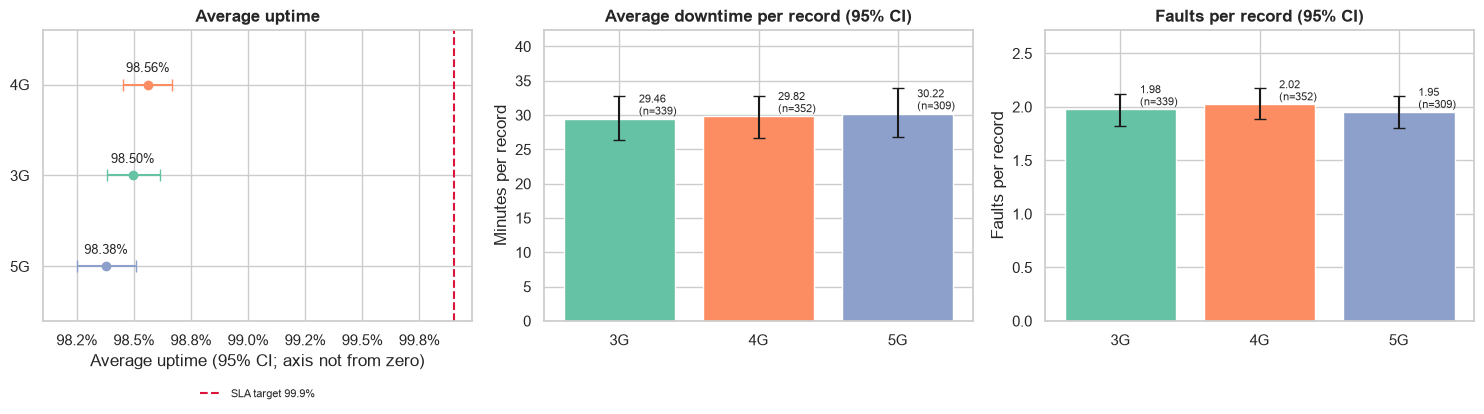

**Interpretation.** 4G has the highest *total* downtime (10,498 min) with 35.2% of records and 35.2% of downtime. 5G has the highest *average downtime per record* (30.22 min), and 5G the lowest average uptime (98.38%). Where the leaders differ, totals are mostly reflecting how many records a technology has, not that it is worse. Uptime by technology: no statistically detectable difference (Holm p = 0.335); downtime by technology: no statistically detectable difference (Holm p = 0.952). A technology difference is an **observed association** only: sites differ in many other ways (age, vendor, location, load) that this data does not capture.

In [12]:
say("**Record coverage and totals by technology**")
display(by_tech[["records", "sites", "days", "records_share_pct", "total_downtime", "downtime_share_pct", "total_faults", "faults_share_pct"]].round(2))
say("**Normalised KPIs by technology**")
display(by_tech[["avg_uptime", "uptime_gap_pp", "pct_records_below_benchmark", "avg_downtime", "faults_per_record", "avg_traffic"]].round(2))
say("**Which technology leads on each metric:**")
display(leader_table(by_tech))

tech_order = by_tech.sort_values("avg_uptime").index.tolist()
palette = dict(zip(sorted(by_tech.index), sns.color_palette("Set2", len(by_tech))))
ci_up = cluster_bootstrap_ci(data, "NetworkType", "Uptime")
ci_dn = cluster_bootstrap_ci(data, "NetworkType", "Downtime")
ci_fl = cluster_bootstrap_ci(data, "NetworkType", "Faults")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]
m = by_tech.loc[tech_order, "avg_uptime"]
for y, t in enumerate(tech_order):
    ax.errorbar(m[t], y, xerr=[[m[t] - ci_up.loc[t, "lo"]], [ci_up.loc[t, "hi"] - m[t]]], fmt="o", color=palette[t], capsize=4)
    ax.annotate(f"{m[t]:.2f}%", (m[t], y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.axvline(UPTIME_BENCHMARK, color="crimson", ls="--", label=f"SLA target {UPTIME_BENCHMARK}%")
ax.set_yticks(range(len(tech_order))); ax.set_yticklabels(tech_order)
ax.set_xlim(ci_up["lo"].min() - 0.15, UPTIME_BENCHMARK + 0.08)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
ax.set_ylim(-0.6, len(tech_order) - 0.4)
ax.set_xlabel("Average uptime (95% CI; axis not from zero)"); ax.set_title("Average uptime")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8, frameon=False)

for ax, col, ci, title, ylab in [(axes[1], "avg_downtime", ci_dn, "Average downtime per record", "Minutes per record"),
                                 (axes[2], "faults_per_record", ci_fl, "Faults per record", "Faults per record")]:
    vals = by_tech.loc[sorted(by_tech.index), col]
    ci_t = ci_dn if col == "avg_downtime" else ci_fl
    ax.bar(vals.index, vals.values, color=[palette[t] for t in vals.index],
           yerr=[vals.values - ci_t.loc[vals.index, "lo"].values, ci_t.loc[vals.index, "hi"].values - vals.values], capsize=4)
    for i, t in enumerate(vals.index):
        ax.annotate(f"{vals[t]:.2f}\n(n={int(by_tech.loc[t, 'records'])})", (i, vals[t]), textcoords="offset points", xytext=(14, 3), ha="left", fontsize=8)
    ax.set_ylim(0, ci_t["hi"].max() * 1.25); ax.set_ylabel(ylab); ax.set_title(title + " (95% CI)")
plt.tight_layout(); plt.show()

st_u, st_d = stat_results[("Uptime", "NetworkType")], stat_results[("Downtime", "NetworkType")]
say(f"**Interpretation.** {t_total} has the highest *total* downtime ({by_tech.loc[t_total, 'total_downtime']:,.0f} min) with "
    f"{by_tech.loc[t_total, 'records_share_pct']:.1f}% of records and {by_tech.loc[t_total, 'downtime_share_pct']:.1f}% of downtime. "
    f"{t_avg} has the highest *average downtime per record* ({by_tech.loc[t_avg, 'avg_downtime']:.2f} min), and {t_lowup} the lowest average uptime "
    f"({by_tech.loc[t_lowup, 'avg_uptime']:.2f}%). Where the leaders differ, totals are mostly reflecting how many records a technology has, not that it is worse. "
    f"Uptime by technology: {'no statistically detectable difference' if st_u['p_anova_holm'] >= 0.05 else 'detectable difference'} (Holm p = {st_u['p_anova_holm']:.3f}); "
    f"downtime by technology: {'no statistically detectable difference' if st_d['p_anova_holm'] >= 0.05 else 'detectable difference'} (Holm p = {st_d['p_anova_holm']:.3f}). "
    f"A technology difference is an **observed association** only: sites differ in many other ways (age, vendor, location, load) that this data does not capture.")


## 12. Daily trends and temporal patterns
Each day contains a different number of records, so a daily average is sometimes based on few observations. The record counts are shown beneath the trend charts for that reason.

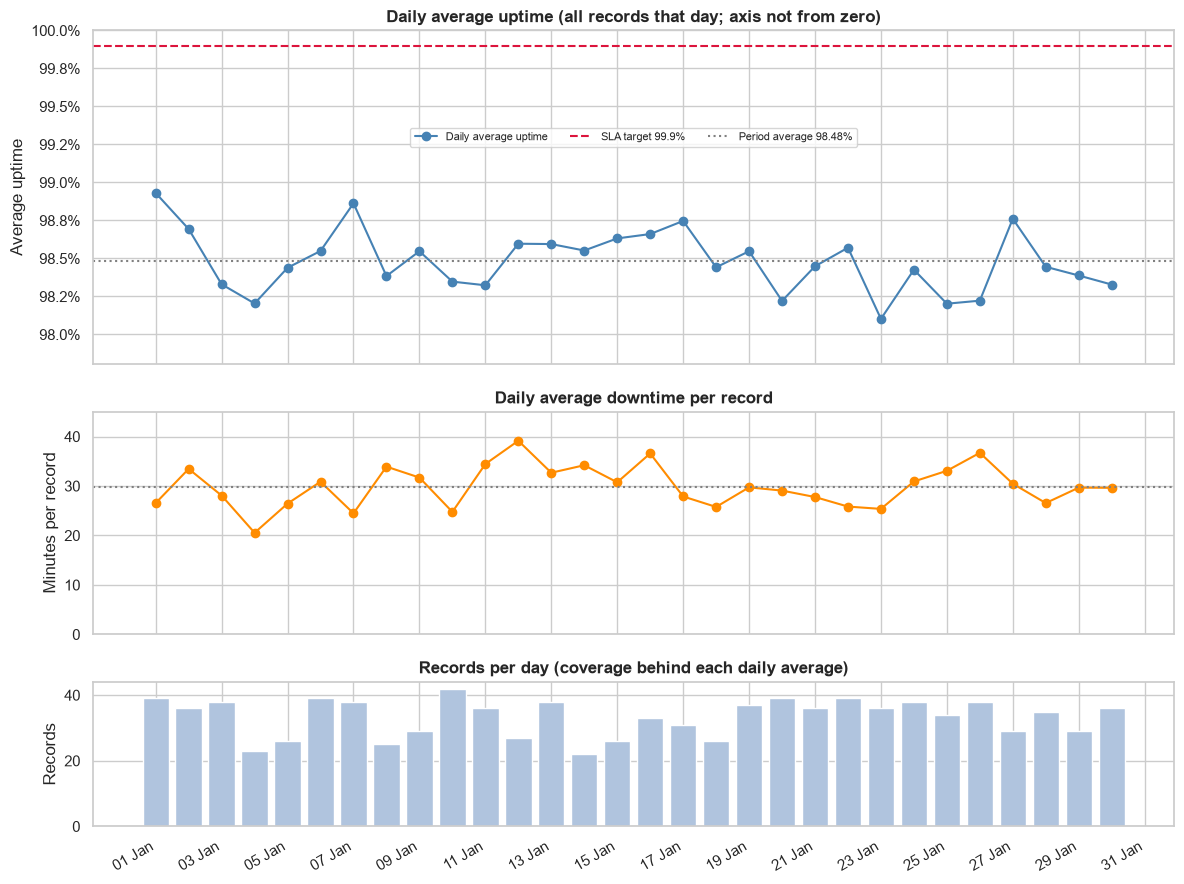

**Interpretation.** Daily average uptime ranges from 98.10% (23 Jan, n=36) to 98.93% (01 Jan, n=39). Daily average uptime varies during the observation period. However, differences in daily record counts, SiteID composition and unresolved observation dependencies prevent us from reliably separating operational changes from sampling variation. The daily results are therefore interpreted descriptively.

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [3, 2, 1.3]})
axes[0].plot(daily.index, daily["avg_uptime"], marker="o", color="steelblue", label="Daily average uptime")
axes[0].axhline(UPTIME_BENCHMARK, color="crimson", ls="--", label=f"SLA target {UPTIME_BENCHMARK}%")
axes[0].axhline(ov["avg_uptime"], color="grey", ls=":", label=f"Period average {ov['avg_uptime']:.2f}%")
axes[0].set_ylim(daily["avg_uptime"].min() - 0.3, 100); axes[0].yaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
axes[0].set_ylabel("Average uptime"); axes[0].set_title("Daily average uptime (all records that day; axis not from zero)")
axes[0].legend(fontsize=8, ncol=3, loc="center", bbox_to_anchor=(0.5, 0.68))

axes[1].plot(daily.index, daily["avg_downtime"], marker="o", color="darkorange")
axes[1].axhline(ov["avg_downtime"], color="grey", ls=":")
axes[1].set_ylim(0, daily["avg_downtime"].max() * 1.15); axes[1].set_ylabel("Minutes per record"); axes[1].set_title("Daily average downtime per record")

axes[2].bar(daily.index, daily["records"], color="lightsteelblue")
axes[2].set_ylabel("Records"); axes[2].set_title("Records per day (coverage behind each daily average)")
axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=2)); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


expected_sd = float(np.sqrt((data["Uptime"].var(ddof=1) / daily["records"]).mean()))
observed_sd = float(daily["avg_uptime"].std(ddof=1))
ratio = observed_sd / expected_sd
worst_day, best_day = daily["avg_uptime"].idxmin(), daily["avg_uptime"].idxmax()
say(f"**Interpretation.** Daily average uptime ranges from {daily['avg_uptime'].min():.2f}% ({worst_day:%d %b}, n={int(daily.loc[worst_day, 'records'])}) "
    f"to {daily['avg_uptime'].max():.2f}% ({best_day:%d %b}, n={int(daily.loc[best_day, 'records'])}). "
    + "Daily average uptime varies during the observation period. However, differences in daily record counts, SiteID composition and unresolved observation dependencies prevent us from reliably separating operational changes from sampling variation. The daily results are therefore interpreted descriptively.")


,records,days,avg_uptime,avg_downtime,faults_per_record
weekday,,,,,
Monday,128,4,98.44,33.11,2.12
Tuesday,145,4,98.52,30.77,1.99
Wednesday,131,4,98.59,27.57,1.89
Thursday,158,5,98.61,28.80,2.02
Friday,170,5,98.46,31.24,1.98
Saturday,149,4,98.45,27.82,1.91
Sunday,119,4,98.29,29.47,2.01


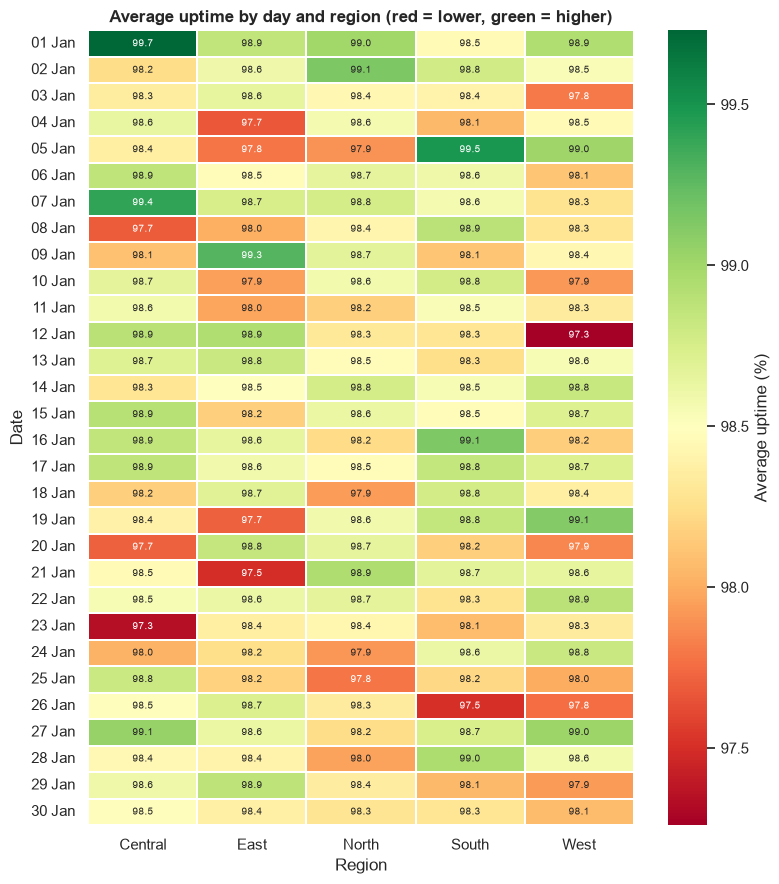

Each heatmap cell averages a median of 7 records (min 2, max 14), and 0 day-region cells have no data. Isolated dark cells are expected from small samples and should not be read as incidents.

In [14]:
# Day-of-week view (descriptive only: about four weeks of data cannot establish a weekly cycle)
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = (data.assign(weekday=data["Day"].dt.day_name()).groupby("weekday")
       .agg(records=("Uptime", "size"), days=("Day", "nunique"), avg_uptime=("Uptime", "mean"),
            avg_downtime=("Downtime", "mean"), faults_per_record=("Faults", "mean"))
       .reindex(dow_order).dropna(how="all"))
display(dow.round(2))

# Daily heatmap: average uptime by day and region
hm = data.pivot_table(index="Day", columns="Region", values="Uptime", aggfunc="mean")
cell_n = data.pivot_table(index="Day", columns="Region", values="Uptime", aggfunc="size")
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(hm.set_axis(hm.index.strftime("%d %b"), axis=0), cmap="RdYlGn", annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Average uptime (%)"}, linewidths=0.3, ax=ax)
ax.set_title("Average uptime by day and region (red = lower, green = higher)"); ax.set_xlabel("Region"); ax.set_ylabel("Date")
plt.tight_layout(); plt.show()
say(f"Each heatmap cell averages a median of {cell_n.stack().median():.0f} records (min {int(cell_n.stack().min())}, max {int(cell_n.stack().max())}), "
    f"and {int(hm.isna().sum().sum())} day-region cells have no data. Isolated dark cells are expected from small samples and should not be read as incidents.")

## 13. SiteID-group exploratory analysis and prioritisation
SiteID-group averages are only as reliable as the number of observations behind them, so SiteID groups with fewer than `MIN_OBS_PER_SITE` observations are not ranked. The priority score is a **transparent heuristic**: the mean percentile rank of (lower average uptime, higher average downtime, higher faults per observation). It orders SiteID groups for review; it is an analyst-defined exploratory SiteID-group screening score, not a validated risk model.


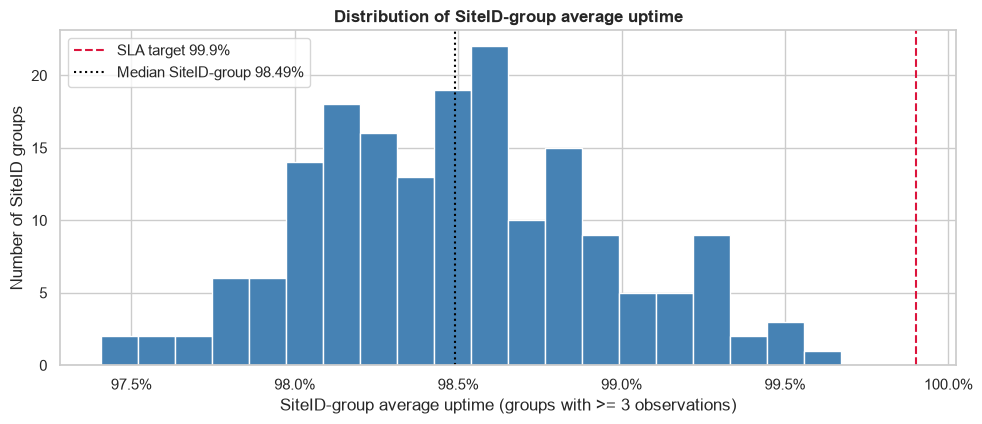

**Top 15 SiteID groups for review (heuristic priority)**

,n_obs,regions,technologies,avg_uptime,uptime_gap_pp,pct_obs_below_benchmark,avg_downtime,total_downtime,total_faults,faults_per_obs,priority_score
SiteID,,,,,,,,,,,
T115,4,East/North/South/West,3G/4G/5G,98.02,1.88,100.00,33.60,134.42,13,3.25,0.85
T037,3,Central/North/South,5G,97.44,2.46,100.00,31.10,93.31,8,2.67,0.83
T044,6,Central/North/South/West,4G/5G,98.31,1.59,83.33,52.60,315.62,17,2.83,0.82
T075,3,North/South,3G/5G,98.17,1.73,100.00,55.77,167.32,7,2.33,0.82
T072,9,Central/East/North/South/West,3G/4G/5G,97.96,1.94,100.00,27.82,250.37,28,3.11,0.80
T101,7,Central/North/South/West,3G/4G/5G,97.91,1.99,100.00,27.40,191.78,20,2.86,0.78
T076,5,Central/East/North/West,3G/4G/5G,98.07,1.83,100.00,29.89,149.43,15,3.00,0.78
T124,6,Central/East/North/West,3G/4G/5G,98.33,1.57,100.00,48.97,293.84,14,2.33,0.76
T073,4,Central/North/South/West,3G/4G/5G,97.92,1.98,100.00,42.23,168.92,8,2.00,0.76



Concentration: the 18 SiteID groups with the most downtime (top 10%) hold 13.6% of observations but 21.9% of downtime.
Records with downtime > 60 min: 131 (13.1% of records) across 98 sites, holding 40.6% of all downtime (for context, the 95th percentile of record downtime is 89.1 min).


**Interpretation.** These SiteID groups are *candidates for investigation*, not confirmed problem sites. With only a few observations per SiteID group, a SiteID group can rank high by chance. The most useful next check is whether the same sites also appear poor in an independent period or in their alarm and ticket history.

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(eligible["avg_uptime"], bins=20, color="steelblue", edgecolor="white")
ax.axvline(UPTIME_BENCHMARK, color="crimson", ls="--", label=f"SLA target {UPTIME_BENCHMARK}%")
ax.axvline(eligible["avg_uptime"].median(), color="black", ls=":", label=f"Median SiteID-group {eligible['avg_uptime'].median():.2f}%")
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.1f%%"))
ax.set_xlabel(f"SiteID-group average uptime (groups with >= {MIN_OBS_PER_SITE} observations)"); ax.set_ylabel("Number of SiteID groups")
ax.set_title("Distribution of SiteID-group average uptime"); ax.legend()
plt.tight_layout(); plt.show()

top = eligible.sort_values("priority_score", ascending=False).head(15)
show_cols = ["n_obs", "regions", "technologies", "avg_uptime", "uptime_gap_pp", "pct_obs_below_benchmark",
             "avg_downtime", "total_downtime", "total_faults", "faults_per_obs", "priority_score"]
top_view = top[show_cols].round(2)

if MASTER_JOIN_OK:
    mm = master.copy()
    mm["_key"] = norm_key(mm[MASTER_KEY])
    attrs = mm.drop(columns=[MASTER_KEY]).set_index("_key").add_prefix("master_").iloc[:, :6]
    tv = top_view.copy()
    tv["_key"] = norm_key(tv.index.to_series()).to_numpy()
    tv = tv.merge(attrs, left_on="_key", right_index=True, how="left", validate="m:1")
    tv.insert(1, "in_master", tv["_key"].isin(attrs.index))
    top_view = tv.drop(columns="_key")
    say(f"Master attributes attached for **{int(top_view['in_master'].sum())} of {len(top_view)}** listed sites (left join; blanks mean the site is not in the master).")

say("**Top 15 SiteID groups for review (heuristic priority)**")
display(top_view)

# Concentration: do a few sites account for a disproportionate share of downtime?
k = max(1, int(round(0.10 * len(eligible))))
conc = eligible.sort_values("total_downtime", ascending=False).head(k)["total_downtime"].sum() / eligible["total_downtime"].sum() * 100
obs_share = eligible.sort_values("total_downtime", ascending=False).head(k)["n_obs"].sum() / eligible["n_obs"].sum() * 100
print(f"\nConcentration: the {k} SiteID groups with the most downtime (top 10%) hold {obs_share:.1f}% of observations but {conc:.1f}% of downtime.")

long_thr = 60   # threshold carried over from the original notebook; it is arbitrary, shown with percentile context
long_recs = data[data["Downtime"] > long_thr]
print(f"Records with downtime > {long_thr} min: {len(long_recs)} ({100 * len(long_recs) / len(data):.1f}% of records) across "
      f"{long_recs['SiteID'].nunique()} sites, holding {100 * long_recs['Downtime'].sum() / data['Downtime'].sum():.1f}% of all downtime "
      f"(for context, the 95th percentile of record downtime is {data['Downtime'].quantile(0.95):.1f} min).")
say("**Interpretation.** These SiteID groups are *candidates for investigation*, not confirmed problem sites. With only a few observations per SiteID group, a SiteID group can rank high by chance. "
    "The most useful next check is whether the same sites also appear poor in an independent period or in their alarm and ticket history.")


In [16]:
# --- 13.1 Sensitivity analysis: observation threshold for site ranking --------
# The main ranking uses MIN_OBS_PER_SITE = 3. Here we check how the eligible set and
# top-priority list change when the threshold is raised to 5 or 10 observations.
thresholds = [3, 5, 10]
sens_rows = []
for thr in thresholds:
    elig = site_stats[site_stats['n_obs'] >= thr].copy()
    elig['priority_score'] = pd.concat([
        (-elig['avg_uptime']).rank(pct=True),
        elig['avg_downtime'].rank(pct=True),
        elig['faults_per_obs'].rank(pct=True)], axis=1).mean(axis=1)
    top5 = elig.sort_values('priority_score', ascending=False).head(5).index.tolist()
    sens_rows.append({
        'threshold': thr,
        'eligible_sites': len(elig),
        'pct_of_all_sites': 100 * len(elig) / len(site_stats),
        'top5_sites': ', '.join(top5),
        'top5_overlap_with_thr3': len(set(top5) & set(top_sites)),
    })
sens = pd.DataFrame(sens_rows)
display(sens[['threshold', 'eligible_sites', 'pct_of_all_sites', 'top5_overlap_with_thr3']].round(1))
print("\nTop-5 priority SiteID groups by threshold:")
for _, r in sens.iterrows():
    print(f"  >= {int(r['threshold'])} obs ({int(r['eligible_sites'])} sites): {r['top5_sites']}")

say("**Interpretation.** Raising the threshold reduces the eligible pool and can change the ranking. "
    "A SiteID group that appears in the top 5 under multiple thresholds is a more stable candidate for review. "
    "SiteID groups that appear only at threshold = 3 should be treated with extra caution because their ranking is more sensitive to a single observation.")


,threshold,eligible_sites,pct_of_all_sites,top5_overlap_with_thr3
0,3,179,89.9,5
1,5,112,56.3,2
2,10,6,3.0,0



Top-5 priority SiteID groups by threshold:
  >= 3 obs (179 sites): T115, T037, T044, T075, T072
  >= 5 obs (112 sites): T044, T072, T076, T101, T124
  >= 10 obs (6 sites): T090, T008, T033, T113, T061


**Interpretation.** Raising the threshold reduces the eligible pool and can change the ranking. A SiteID group that appears in the top 5 under multiple thresholds is a more stable candidate for review. SiteID groups that appear only at threshold = 3 should be treated with extra caution because their ranking is more sensitive to a single observation.

## 14. Statistical analysis
**Why these tests.** The original notebook ran two one-way ANOVAs. They are kept, extended to all four combinations of {uptime, downtime} x {region, technology} (so the uptime comparison between technologies quoted in the summary is actually tested), and made more careful:

* **Business question:** is the average level of the metric different between groups?
* **Null hypothesis:** the group means are equal.
* **Observation unit:** one record (a site observation on a date). Records are *not* guaranteed to be independent, because the same site can appear several times.
* **Handling repeated sites:** the intraclass correlation (ICC) by `SiteID` measures how alike observations within the same SiteID group are. Confidence intervals in the charts use a **SiteID-group bootstrap** that keeps each SiteID group's records together. A SiteID-group-averaged test is not used, because `SiteID` does not map to a single region or technology in this data.
* **Robustness:** Kruskal-Wallis (rank-based) is reported alongside ANOVA because uptime and downtime are unlikely to be normal. Levene's test checks equal variances. With about a thousand records, formal normality tests flag trivial departures, so skewness is shown instead.
* **Multiple testing:** four tests are run, so Holm-adjusted p-values are reported.
* **Effect size:** eta-squared is the share of variance explained by the grouping (about 0.01 small, 0.06 medium, 0.14 large).


In [17]:
summary_rows = []
for (val, grp), r in stat_results.items():
    say(f"#### {val} by {grp}")
    display(r["desc"].round(3))
    print(f"ANOVA: F = {r['F']:.3f}, p = {r['p_anova']:.4f} (Holm-adjusted {r['p_anova_holm']:.4f}) | "
          f"Kruskal-Wallis: H = {r['H']:.3f}, p = {r['p_kruskal']:.4f} (Holm {r['p_kruskal_holm']:.4f})")
    print(f"Levene (equal variances) p = {r['p_levene']:.4f} | skewness of {val} = {r['skew']:.2f} | ICC by SiteID = {r['icc_site']:.3f}")
    print(f"Effect size eta-squared = {r['eta_sq']:.4f} ({eta_label(r['eta_sq'])}) | spread of group means = {r['range_of_means']:.3f}\n")
    summary_rows.append({"metric": val, "grouping": grp, "F": r["F"], "p_ANOVA": r["p_anova"], "p_ANOVA_Holm": r["p_anova_holm"],
                         "p_Kruskal": r["p_kruskal"], "p_Kruskal_Holm": r["p_kruskal_holm"], "eta_sq": r["eta_sq"]})
say("**Summary of the four comparisons**")
display(pd.DataFrame(summary_rows).round(4))

#### Uptime by Region

,n,mean,sd,median
Region,,,,
Central,202,98.568,1.134,98.715
East,203,98.480,1.017,98.550
North,186,98.466,1.022,98.540
South,196,98.527,1.045,98.615
West,213,98.379,1.081,98.420


ANOVA: F = 0.930, p = 0.4459 (Holm-adjusted 0.9140) | Kruskal-Wallis: H = 4.119, p = 0.3901 (Holm 1.0000)
Levene (equal variances) p = 0.2236 | skewness of Uptime = -0.41 | ICC by SiteID = -0.032
Effect size eta-squared = 0.0037 (negligible) | spread of group means = 0.189



#### Downtime by NetworkType

,n,mean,sd,median
NetworkType,,,,
3G,339,29.464,29.462,21.390
4G,352,29.824,30.532,19.555
5G,309,30.223,32.278,20.390


ANOVA: F = 0.049, p = 0.9519 (Holm-adjusted 0.9519) | Kruskal-Wallis: H = 0.370, p = 0.8313 (Holm 1.0000)
Levene (equal variances) p = 0.7126 | skewness of Downtime = 2.02 | ICC by SiteID = 0.016
Effect size eta-squared = 0.0001 (negligible) | spread of group means = 0.759



... (4 outputs left out)

,n,mean,sd,median
Region,,,,
Central,202,29.526,30.711,19.815
East,203,33.940,34.193,24.410
North,186,28.039,26.737,18.625
South,196,29.029,31.285,20.385
West,213,28.479,29.792,19.250


ANOVA: F = 1.210, p = 0.3047 (Holm-adjusted 0.9140) | Kruskal-Wallis: H = 3.894, p = 0.4206 (Holm 1.0000)
Levene (equal variances) p = 0.4392 | skewness of Downtime = 2.02 | ICC by SiteID = 0.016
Effect size eta-squared = 0.0048 (negligible) | spread of group means = 5.901



**Summary of the four comparisons**

,metric,grouping,F,p_ANOVA,p_ANOVA_Holm,p_Kruskal,p_Kruskal_Holm,eta_sq
0,Uptime,Region,0.9297,0.4459,0.9140,0.3901,1.0000,0.0037
1,Downtime,NetworkType,0.0493,0.9519,0.9519,0.8313,1.0000,0.0001
2,Uptime,NetworkType,2.4871,0.0837,0.3347,0.1219,0.4875,0.0050
3,Downtime,Region,1.2105,0.3047,0.9140,0.4206,1.0000,0.0048


In [18]:
interp = []
for (val, grp), r in stat_results.items():
    agree = (r["p_anova_holm"] < 0.05) == (r["p_kruskal_holm"] < 0.05)
    if r["p_anova_holm"] < 0.05:
        txt = (f"* **{val} by {grp}:** a difference is statistically detectable (Holm p = {r['p_anova_holm']:.3f}). Its practical size is "
               f"{eta_label(r['eta_sq'])} (eta-squared {r['eta_sq']:.3f}; group means span {r['range_of_means']:.2f}). Statistical significance does not show cause.")
    else:
        txt = (f"* **{val} by {grp}:** no difference is detectable (Holm p = {r['p_anova_holm']:.3f}; eta-squared {r['eta_sq']:.3f}, {eta_label(r['eta_sq'])}). "
               f"This does not establish that the groups are equivalent, nor does it rule out differences that the available data and analytical assumptions cannot reliably detect.")
    if not agree:
        txt += " ANOVA and Kruskal-Wallis disagree, so treat the result as uncertain."
    interp.append(txt)
icc_vals = [r["icc_site"] for r in stat_results.values() if not np.isnan(r["icc_site"])]
icc_max = max(icc_vals) if icc_vals else float("nan")
interp.append(f"* **Repeated SiteID identifiers:** the largest estimated ICC across the four metrics is {icc_max:.3f}. "
              + ("Estimated values are close to zero, suggesting limited within-SiteID similarity in this sample. However, this does not establish independence between observations. The meaning and stability of SiteID remain unresolved, and other dependencies, including shared observation dates, are not assessed. Statistical results should therefore be interpreted cautiously. "
                 if icc_max < 0.1 else
                 "A non-trivial ICC means records from the same SiteID are alike, so the ANOVA p-values are likely **too optimistic**; rely on descriptive comparisons and treat inferential results cautiously. ")
              + "With few observations per SiteID group, the ICC estimate itself is imprecise.")
say("**Plain-language interpretation**\n\n" + "\n".join(interp))

say("#### Relationships between metrics (record level, Spearman rank correlation)")
spear = data[["Uptime", "Downtime", "Faults", "Traffic"]].corr(method="spearman")
display(spear.round(3))
off = spear.where(~np.eye(len(spear), dtype=bool)).abs().stack()
pair = off.idxmax()
say(f"The strongest relationship is between **{pair[0]}** and **{pair[1]}** (rho = {spear.loc[pair[0], pair[1]]:.3f}). "
    + ("No strong monotonic pairwise associations were observed among these metrics. Correlation does not rule out nonlinear or confounded relationships. " if off.max() < 0.3 else "")
    + "Correlation shows association only. In particular, a weak Uptime-Downtime correlation is a **data-consistency warning** (Section 5), not evidence that downtime does not affect uptime.")


**Plain-language interpretation**

* **Uptime by Region:** no difference is detectable (Holm p = 0.914; eta-squared 0.004, negligible). This does not establish that the groups are equivalent, nor does it rule out differences that the available data and analytical assumptions cannot reliably detect.
* **Downtime by NetworkType:** no difference is detectable (Holm p = 0.952; eta-squared 0.000, negligible). This does not establish that the groups are equivalent, nor does it rule out differences that the available data and analytical assumptions cannot reliably detect.
* **Uptime by NetworkType:** no difference is detectable (Holm p = 0.335; eta-squared 0.005, negligible). This does not establish that the groups are equivalent, nor does it rule out differences that the available data and analytical assumptions cannot reliably detect.
* **Downtime by Region:** no difference is detectable (Holm p = 0.914; eta-squared 0.005, negligible). This does not establish that the groups are equivalent, nor does it rule out differences that the available data and analytical assumptions cannot reliably detect.
* **Repeated SiteID identifiers:** the largest estimated ICC across the four metrics is 0.016. Estimated values are close to zero, suggesting limited within-SiteID similarity in this sample. However, this does not establish independence between observations. The meaning and stability of SiteID remain unresolved, and other dependencies, including shared observation dates, are not assessed. Statistical results should therefore be interpreted cautiously. With few observations per SiteID group, the ICC estimate itself is imprecise.

#### Relationships between metrics (record level, Spearman rank correlation)

,Uptime,Downtime,Faults,Traffic
Uptime,1.000,0.043,-0.053,0.041
Downtime,0.043,1.000,0.014,0.011
Faults,-0.053,0.014,1.000,0.031
Traffic,0.041,0.011,0.031,1.000


The strongest relationship is between **Uptime** and **Faults** (rho = -0.053). No strong monotonic pairwise associations were observed among these metrics. Correlation does not rule out nonlinear or confounded relationships. Correlation shows association only. In particular, a weak Uptime-Downtime correlation is a **data-consistency warning** (Section 5), not evidence that downtime does not affect uptime.

## 15. Evidence-based recommendations
Each item is tied to a result above. Findings, recommendations, hypotheses and quantified impact are kept separate so that an untested idea is never mistaken for a measured result.

In [19]:
reg_not_sig = stat_results[("Uptime", "Region")]["p_anova_holm"] >= 0.05
tech_not_sig = stat_results[("Uptime", "NetworkType")]["p_anova_holm"] >= 0.05 and stat_results[("Downtime", "NetworkType")]["p_anova_holm"] >= 0.05

recs = ["### A. Findings this section relies on (from Sections 8-14)",
        f"* Network-wide mean uptime is {ov['uptime_gap_pp']:.2f} pp below target; {n_elig - n_meet} of {n_elig} rankable SiteID groups are below target on average (proxy).",
        f"* Regional spread is {reg_spread:.2f} pp; regional difference is {'not ' if reg_not_sig else ''}statistically detectable.",
        f"* The top 10% of eligible SiteID groups by downtime hold {conc:.1f}% of downtime (vs {obs_share:.1f}% of observations).",
        "", "### B. Recommendations (practical next steps)"]
n = 1
if dq_flags:
    recs.append(f"{n}. **Confirm data definitions before operational use.** {len(dq_flags)} data-quality items were flagged (Section 5), e.g. "
                f"{'; '.join(f.split(':')[0] for f in dq_flags[:3])}. Ask the data owner how Uptime, Downtime and SiteID are defined. *Why:* conclusions depend on them.")
    n += 1
recs.append(f"{n}. **Run a desk review of the priority SiteID groups** ({', '.join(top_sites)}): pull alarm, ticket and maintenance history for the same period and check whether the poor performance repeats. "
            "*Why:* these SiteID groups rank worst on the heuristic score, but small samples can mislead.")
n += 1
if reg_not_sig and tech_not_sig:
    recs.append(f"{n}. **Do not allocate resources by region or technology on this evidence alone.** Differences between groups are small relative to the network-wide gap "
                f"and not statistically detectable. Investigate network-wide drivers and the site-level exceptions instead.")
else:
    recs.append(f"{n}. **Review the weaker groups first, but confirm at site level.** At least one region or technology comparison is statistically detectable (Section 14); "
                f"check whether the effect holds up in site-level data before acting.")
n += 1
if conc > obs_share * 1.5:
    recs.append(f"{n}. **Focus on the high-downtime tail.** Downtime is concentrated in a minority of SiteID groups ({conc:.1f}% from the top 10%), so a targeted pilot on those SiteID groups is more promising than network-wide measures.")
else:
    recs.append(f"{n}. **Do not assume a small group of sites explains the shortfall.** Downtime is not strongly concentrated in a few sites in this data.")
n += 1
recs.append(f"{n}. **Collect the missing fields** (Section 16) so that causes, durations and costs can be analysed.")
n += 1
recs.append(f"{n}. **If an intervention is trialled,** define the success metric and comparison sites in advance and measure before and after. Only then can an improvement or saving be quantified.")
recs += ["", "### C. Hypotheses (untested; this data cannot confirm or reject them)",
         "* Site-specific factors such as power, backhaul or equipment condition may drive the high-downtime sites.",
         "* Older or heavily loaded sites may perform worse. The data has no site age, vendor or capacity field, so this is not tested.",
         "* Seasonal conditions may affect availability. One month of data cannot test this.",
         "", "### D. Quantified impact estimates",
         "**None are provided.** The original notebook's figures (+0.5 pp uptime, 95 % compliance, INR 1-2 crore annual savings, fewer truck rolls) had no supporting calculation or cost data and were removed. "
         "Estimating them would need intervention cost, field-visit volume, outage duration and a defined SLA penalty or revenue-loss formula."]
say("\n".join(recs))

### A. Findings this section relies on (from Sections 8-14)
* Network-wide mean uptime is 1.42 pp below target; 179 of 179 rankable SiteID groups are below target on average (proxy).
* Regional spread is 0.19 pp; regional difference is not statistically detectable.
* The top 10% of eligible SiteID groups by downtime hold 21.9% of downtime (vs 13.6% of observations).

### B. Recommendations (practical next steps)
1. **Confirm data definitions before operational use.** 6 data-quality items were flagged (Section 5), e.g. Rows sharing a SiteID + Date with another row; Sites recorded under more than one Region; Sites recorded under more than one NetworkType. Ask the data owner how Uptime, Downtime and SiteID are defined. *Why:* conclusions depend on them.
2. **Run a desk review of the priority SiteID groups** (T115, T037, T044, T075, T072): pull alarm, ticket and maintenance history for the same period and check whether the poor performance repeats. *Why:* these SiteID groups rank worst on the heuristic score, but small samples can mislead.
3. **Do not allocate resources by region or technology on this evidence alone.** Differences between groups are small relative to the network-wide gap and not statistically detectable. Investigate network-wide drivers and the site-level exceptions instead.
4. **Focus on the high-downtime tail.** Downtime is concentrated in a minority of SiteID groups (21.9% from the top 10%), so a targeted pilot on those SiteID groups is more promising than network-wide measures.
5. **Collect the missing fields** (Section 16) so that causes, durations and costs can be analysed.
6. **If an intervention is trialled,** define the success metric and comparison sites in advance and measure before and after. Only then can an improvement or saving be quantified.

### C. Hypotheses (untested; this data cannot confirm or reject them)
* Site-specific factors such as power, backhaul or equipment condition may drive the high-downtime sites.
* Older or heavily loaded sites may perform worse. The data has no site age, vendor or capacity field, so this is not tested.
* Seasonal conditions may affect availability. One month of data cannot test this.

### D. Quantified impact estimates
**None are provided.** The original notebook's figures (+0.5 pp uptime, 95 % compliance, INR 1-2 crore annual savings, fewer truck rolls) had no supporting calculation or cost data and were removed. Estimating them would need intervention cost, field-visit volume, outage duration and a defined SLA penalty or revenue-loss formula.

## 16. Limitations and future enhancements

**Limitations**
* **No causal or root-cause information.** There are no fault categories, equipment, power, backhaul, maintenance or incident fields, so *why* downtime occurs cannot be determined. Technology and region differences are associations only.
* **SLA metrics are proxies.** The contractual measurement period, formula and exclusions are unknown. Record-level, site-level and daily results here are not contractual compliance, and monthly compliance cannot be computed from sparse observations.
* **Undocumented measurement window and units.** Section 5 tests whether Uptime and Downtime are consistent; they are analysed separately, never converted into one another.
* **Sparse, unbalanced sampling.** Each site has few observations, so site-level averages are noisy; sites may appear under several regions or technologies (see Section 5).
* **Unmatched supplementary master dataset.** The tower master contains 40 records, but none of its identifiers matches the network dataset's SiteID identifiers. No valid relationship could be established. Therefore, the tower master is excluded from analytical joins and network-wide comparisons. An authoritative identifier crosswalk would be required before combining these datasets.
* **Short window.** About one month cannot show seasonality, trends or recurring weekly patterns.
* **Provenance.** The generating process of the dataset is not documented here. Treat the findings as an illustration of method, not as evidence about a real network, unless the data owner confirms otherwise.

**Future enhancements (data needed)**
| Analysis | Fields required |
|---|---|
| Root-cause analysis | Incident ID, start / end timestamps, fault category, cause code, equipment, vendor |
| Contractual SLA compliance | SLA contract definition, measurement period, planned-maintenance exclusions, full daily coverage per site |
| Environment and resilience | Power / grid status, backhaul type, site class, age, capacity |
| Business impact | Field-visit counts, repair cost, penalty or revenue-loss rules |
| Intervention evaluation | Before / after periods, treated and comparison sites |

## 17. Final business conclusions

In [20]:
concl = [
    f"1. **The shortfall is network-wide.** Mean uptime is {ov['avg_uptime']:.2f}% against a {UPTIME_BENCHMARK}% target (gap {ov['uptime_gap_pp']:.2f} pp); "
    f"{ov['pct_records_below_benchmark']:.1f}% of records and {n_elig - n_meet} of {n_elig} rankable SiteID groups (proxy) are below target.",
    f"2. **Regional and technology differences are small** relative to that gap (regions span {reg_spread:.2f} pp; technology averages span "
    f"{by_tech['avg_uptime'].max() - by_tech['avg_uptime'].min():.2f} pp). Leaders differ by metric: {t_total} has the most total downtime, {t_avg} the most downtime per record.",
    "3. **Statistical evidence:** " + "; ".join(
        f"{v} by {g}: {'detectable' if stat_results[(v, g)]['p_anova_holm'] < 0.05 else 'not detectable'}" for v, g in TESTS) + ". "
    "A non-detectable difference is not proof of equality.",
    f"4. **Daily pattern:** daily average uptime varies during the observation period; differences in daily record counts, SiteID composition and unresolved observation dependencies prevent reliable separation of operational changes from sampling variation.",
    f"5. **Where to look next:** the priority SiteID groups in Section 13 ({', '.join(top_sites)}), after the data-definition questions in Section 5 are answered.",
    "6. **What cannot be concluded:** causes of downtime, contractual SLA compliance, or any financial or uptime-improvement estimate.",
]
say("\n".join(concl))


1. **The shortfall is network-wide.** Mean uptime is 98.48% against a 99.9% target (gap 1.42 pp); 87.2% of records and 179 of 179 rankable SiteID groups (proxy) are below target.
2. **Regional and technology differences are small** relative to that gap (regions span 0.19 pp; technology averages span 0.18 pp). Leaders differ by metric: 4G has the most total downtime, 5G the most downtime per record.
3. **Statistical evidence:** Uptime by Region: not detectable; Downtime by NetworkType: not detectable; Uptime by NetworkType: not detectable; Downtime by Region: not detectable. A non-detectable difference is not proof of equality.
4. **Daily pattern:** daily average uptime varies during the observation period; differences in daily record counts, SiteID composition and unresolved observation dependencies prevent reliable separation of operational changes from sampling variation.
5. **Where to look next:** the priority SiteID groups in Section 13 (T115, T037, T044, T075, T072), after the data-definition questions in Section 5 are answered.
6. **What cannot be concluded:** causes of downtime, contractual SLA compliance, or any financial or uptime-improvement estimate.

---
*Reproducibility:* all tables, figures and narrative figures are computed when the notebook runs; no hand-typed result values are used. Bootstrap results use `RNG_SEED`. Charts are displayed inline and no files are written.